# 1. Imports

In [169]:
from pathlib import Path 
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report  ,confusion_matrix , ConfusionMatrixDisplay, f1_score
from mpl_toolkits.mplot3d import Axes3D
from sklearn.linear_model  import LogisticRegression
import warnings
warnings.filterwarnings('ignore')

# 2. Global parameters

In [170]:
RANDOM_STATE=24 #REMEMBER: remove at the time of promotion to production
rng = np.random.default_rng(seed=RANDOM_STATE)

NOISE=0.2
EPOCHS=20001
ALPHA=0.1
N_SAMPLE= 1000
TEST_SIZE=0.2
DIM_H_LAYER = 4
params = {
    'legend.fontsize': 'medium',
    'figure.figsize' : (15,6),
    'axes.labelsize':'medium',
    'axes.titlesize':'medium',
    'xtick.labelsize':'medium',
    'ytick.labelsize':'medium',

}

plt.rcParams.update(params)
CMAP= plt.cm.coolwarm
plt.style.use('seaborn-v0_8-darkgrid') #plt.style.use('ggplot')

## Helper Function

In [171]:
df = sns.load_dataset('iris')
df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [172]:
X,y= df.drop('species', axis=1).to_numpy(), df['species']
X[:5],y[:5]                       

(array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2]]),
 0    setosa
 1    setosa
 2    setosa
 3    setosa
 4    setosa
 Name: species, dtype: object)

In [173]:
y = pd.get_dummies(y).to_numpy()
y.shape

(150, 3)

In [174]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y)

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(120, 4) (30, 4) (120, 3) (30, 3)


## Different Plots

In [175]:
plt.figure()
# plt.scatter(X.iloc[:,0],X.iloc[:,1],s=30,c=y.argmax(axis=1),marker="*",cmap=CMAP)

<Figure size 1500x600 with 0 Axes>

<Figure size 1500x600 with 0 Axes>

## Sigmoid Activation Fucntion

In [176]:
def fn_sigmoid(z):
    return 1 / (1+np.exp(-z))

In [177]:
fn_sigmoid(np.asarray([-np.inf,-1,0,+1,np.inf]))

array([0.        , 0.26894142, 0.5       , 0.73105858, 1.        ])

In [178]:
def fun_softmax(z:np.ndarray)-> np.ndarray:
    z_shifted = z - np.max(z, axis = 1, keepdims=True)
    exp_sc = np.exp(z_shifted)
    return exp_sc / np.sum(exp_sc , axis =1 , keepdims = True)
 

In [179]:
fun_softmax(np.asarray([[8,5,0], [-10,0,+10]]))

array([[9.52269826e-01, 4.74107229e-02, 3.19450938e-04],
       [2.06106005e-09, 4.53978686e-05, 9.99954600e-01]])

## Tanh Activation Function

In [180]:
def fn_activ(z:np.ndarray)-> np.ndarray:
    return np.tanh(z)

def fn_activ_prime(z:np.ndarray)->np.ndarray:
    return  1.0 - np.tanh(z)**2

In [181]:
fn_activ(np.asarray([[-1,0,1],[-np.inf,0,np.inf]]))

array([[-0.76159416,  0.        ,  0.76159416],
       [-1.        ,  0.        ,  1.        ]])

In [182]:
def fn_predict(model: dict, X_p:np.ndarray):
   '''
   model: Dictionary containing weights and bias
   X_p: Input features
   ''' 
   W1,W2,W3 ,W4,W5 = model['W1'],model['W2'],model['W3'],model['W4'],model['W5']
   b1,b2,b3, b4, b5 = model['b1'],model['b2'], model['b3'], model['b4'], model['b5']
   ### Forward propagation
   
   #Layer 1
   z1 = X_p.dot(W1) + b1 #aggregation
   a1 = fn_activ(z1) #Activation   (Tanh)

   #Layer 2
   z2 = a1.dot(W2) + b2 #aggregation
   a2 = fn_activ(z2) #Activation   (Tanh)

   #Layer 3
   z3 = a2.dot(W3) + b3 #aggregation
   a3 = fn_activ(z3) #Activation   (Tanh)

   #Layer 4
   z4 = a3.dot(W4) + b4 #aggregation
   a4 = fn_activ(z4) #Activation   (Tanh)
   
   #Layer 5
   z5 = a4.dot(W5) + b5 #aggregation
   a5 = fun_softmax(z5) #Activation  (Sigmoid)
   
   return np.argmax(a5,axis=1)  

In [183]:
def fn_calculate_loss(model: dict, X_l:np.ndarray,y_l:np.ndarray):
    '''
    model: Dictionary containing weights and bias
    X_l: input features
    y_l:targets
    ''' 
    m=X_l.shape[0]
    
    W1,W2,W3 ,W4,W5 = model['W1'],model['W2'],model['W3'],model['W4'], model['W5']
    b1,b2,b3, b4, b5 = model['b1'],model['b2'], model['b3'], model['b4'], model['b5']
    

    #Layer 1
    z1 = X_l.dot(W1) + b1 #aggregation
    a1 = fn_activ(z1) #Activation   (Tanh)

    #Layer 2
    z2 = a1.dot(W2) + b2 #aggregation
    a2 = fn_activ(z2) #Activation   (Tanh)

    #Layer 3
    z3 = a2.dot(W3) + b3 #aggregation
    a3 = fn_activ(z3) #Activation   (Tanh)

    #Layer 4
    z4 = a3.dot(W4) + b4 #aggregation
    a4 = fn_activ(z4) #Activation   (Tanh)
    
    #Layer 5
    z5 = a4.dot(W5) + b5 #aggregation
    a5 = fun_softmax(z5) #Activation  (Sigmoid)

    eps = 1e-7 
    a5 = np.clip(a5, eps, 1-eps)

    # Categorical Cross-Entropy Loss (using final output a5)
    data_loss = -(y_l * np.log(a5)).sum()
    
    return data_loss / m

In [197]:
def fn_build_model(
    param: dict,
    X: np.ndarray,
    y: np.ndarray,
    alpha: np.float64 = ALPHA,
    n_epochs: np.int64 = EPOCHS,
) -> dict:
  """nn_hdim: number of hidden units,

  X : features
  y = label
  alpha = learning rate
  n_epochs : number of passes through complete data for gradient descent
  """
  m, nn_input_dim = X.shape
  nn_output_dim = y.shape[1]

  W1 = rng.random(
      (param["nn_hdim"][0], param["nn_hdim"][1]), dtype=np.float32
  ) / np.sqrt(param["nn_hdim"][0])
  W2 = rng.random(
      (param["nn_hdim"][1], param["nn_hdim"][2]), dtype=np.float32
  ) / np.sqrt(param["nn_hdim"][1])
  W3 = rng.random(
      (param["nn_hdim"][2], param["nn_hdim"][3]), dtype=np.float32
  ) / np.sqrt(param["nn_hdim"][2])
  W4 = rng.random(
      (param["nn_hdim"][3], param["nn_hdim"][4]), dtype=np.float32
  ) / np.sqrt(param["nn_hdim"][3])
  W5 = rng.random(
      (param["nn_hdim"][4], nn_output_dim), dtype=np.float32
  ) / np.sqrt(param["nn_hdim"][4])

  b1 = np.zeros((1, param["nn_hdim"][1]), dtype=np.float32)
  b2 = np.zeros((1, param["nn_hdim"][2]), dtype=np.float32)
  b3 = np.zeros((1, param["nn_hdim"][3]), dtype=np.float32)
  b4 = np.zeros((1, param["nn_hdim"][4]), dtype=np.float32)
  b5 = np.zeros((1, nn_output_dim), dtype=np.float32)

  curr_loss = 0
  loss, epoch = [], []

  for i in range(n_epochs):  # loop for number of epochs
    # Forward propogation
    # Layer 1
    z1 = X.dot(W1) + b1
    a1 = fn_activ(z1)

    # Layer 2
    z2 = a1.dot(W2) + b2
    a2 = fn_activ(z2)

    # Layer 3
    z3 = a2.dot(W3) + b3
    a3 = fn_activ(z3)

    # Layer 4
    z4 = a3.dot(W4) + b4
    a4 = fn_activ(z4)

    # Layer 5
    z5 = a4.dot(W5) + b5
    a5 = fn_softmax(z5)

    # Back Propogation
    # Layer 5
    dz5 = a5 - y
    dW5 = (a4.T).dot(dz5)
    assert W5.shape == dW5.shape, f"Shape- W5:{W5.shape} | dW5: {dW5.shape}"
    db5 = np.sum(dz5, axis=0, keepdims=True)
    assert b5.shape == db5.shape, f"Shape- b5:{b5.shape} | db5: {db5.shape}"
    da4 = dz5.dot(W5.T)
    assert a4.shape == da4.shape, f"Shape- a4:{a4.shape} | da4:{da4.shape}"

    # Layer 4
    dz4 = da4 * fn_activ_prime(z4)
    dW4 = (a3.T).dot(dz4)
    assert W4.shape == dW4.shape, f"Shape- W4:{W4.shape} | dW4: {dW4.shape}"
    db4 = np.sum(dz4, axis=0, keepdims=True)
    assert b4.shape == db4.shape, f"Shape- b4:{b4.shape} | db4: {db4.shape}"
    da3 = dz4.dot(W4.T)
    assert a3.shape == da3.shape, f"Shape- a3:{a3.shape} | da3:{da3.shape}"

    # Layer 3
    dz3 = da3 * fn_activ_prime(z3)
    dW3 = (a2.T).dot(dz3)
    assert W3.shape == dW3.shape, f"Shape- W3:{W3.shape} | dW3: {dW3.shape}"
    db3 = np.sum(dz3, axis=0, keepdims=True)
    assert b3.shape == db3.shape, f"Shape- b3:{b3.shape} | db3: {db3.shape}"
    da2 = dz3.dot(W3.T)
    assert a2.shape == da2.shape, f"Shape- a2:{a2.shape} | da2:{da2.shape}"

    # Layer 2
    dz2 = da2 * fn_activ_prime(z2)
    dW2 = (a1.T).dot(dz2)
    assert W2.shape == dW2.shape, f"Shape- W2:{W2.shape} | dW2: {dW2.shape}"
    db2 = np.sum(dz2, axis=0, keepdims=True)
    assert b2.shape == db2.shape, f"Shape- b2:{b2.shape} | db2: {db2.shape}"
    da1 = dz2.dot(W2.T)
    assert a1.shape == da1.shape, f"Shape- a1:{a1.shape} | da1:{da1.shape}"

    # Layer 1
    dz1 = da1 * fn_activ_prime(z1)
    dW1 = (X.T).dot(dz1)
    assert W1.shape == dW1.shape, f"Shape- W1:{W1.shape} | dW1:{dW1.shape}"
    db1 = np.sum(dz1, axis=0, keepdims=True)
    assert b1.shape == db1.shape, f"Shape - b1:{b1.shape} | db1:{db1.shape}"

    W1 = W1 - alpha * dW1 / m
    W2 = W2 - alpha * dW2 / m
    W3 = W3 - alpha * dW3 / m
    W4 = W4 - alpha * dW4 / m
    W5 = W5 - alpha * dW5 / m

    b1 = b1 - alpha * db1 / m
    b2 = b2 - alpha * db2 / m
    b3 = b3 - alpha * db3 / m
    b4 = b4 - alpha * db4 / m
    b5 = b5 - alpha * db5 / m

    model = {
        "W1": W1,
        "W2": W2,
        "W3": W3,
        "W4": W4,
        "W5": W5,
        "b1": b1,
        "b2": b2,
        "b3": b3,
        "b4": b4,
        "b5": b5,
    }

    if i % 100 == 0:
      curr_loss = fn_calculate_loss(model=model, X_l=X, y_l=y)
      loss.append(curr_loss)
      epoch.append(i)
      print(f"Epoch {i:3d}: Loss = {curr_loss:.4f}")

  loss_hist["epoch"] = epoch
  loss_hist["loss"] = loss
  return model

In [198]:
loss_hist = {} 
layer_param = {}
layer_param['nn_hdim'] = [X_train.shape[1], 5, 5, 4, 3]
model = fn_build_model(layer_param , X_train, y_train)

NameError: name 'fn_softmax' is not defined

KeyError: 'epoch'

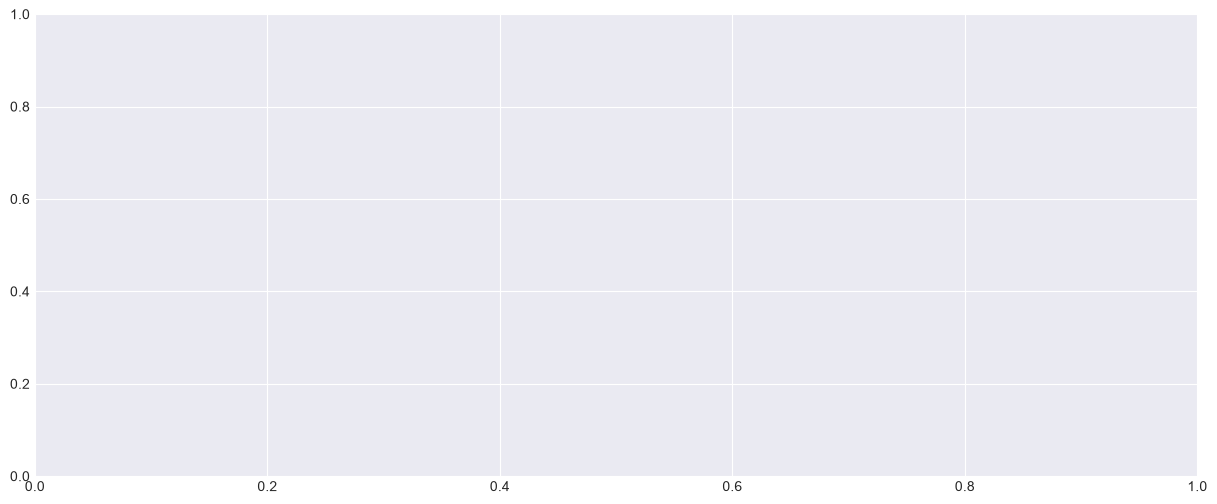

In [199]:
loss_df = pd.DataFrame(loss_hist)
fig , ax = plt.subplots()
loss_df.plot(x='epoch',y='loss',ax=ax)

KeyError: 'epoch'

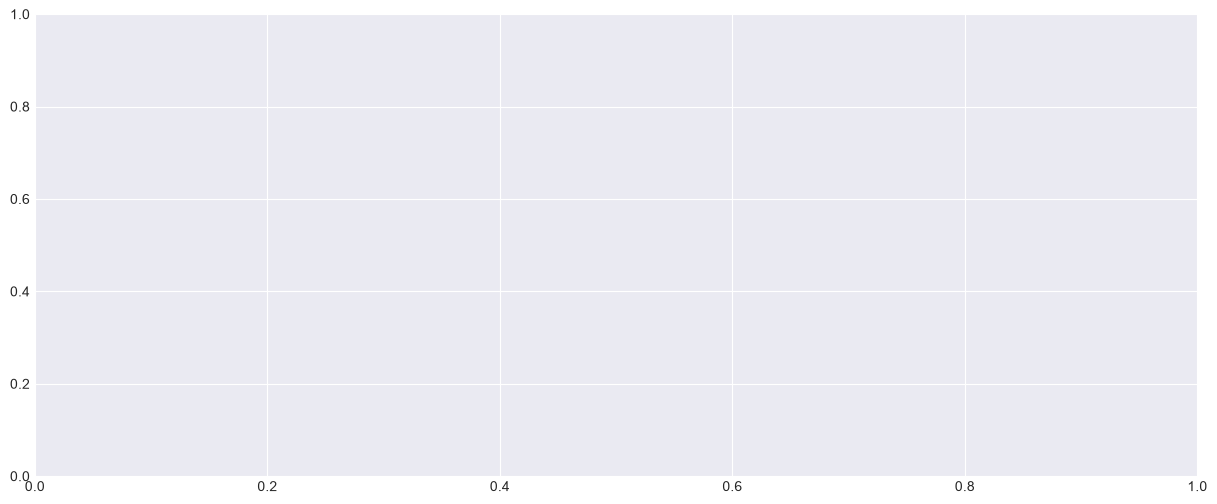

In [200]:
fig, ax = plt.subplots()
# Plot training loss line
ax.plot(loss_df['epoch'], loss_df['loss'], color='#1f77b4',  label='Training Loss')
# Titles and axis labels
ax.set_title('Model Loss Over Epochs')
ax.set_xlabel('Epoch')
ax.set_ylabel('Mean Squared Error')
# Subtle grid and clean borders
ax.grid(True, linestyle='--', alpha=0.5)
final_loss = loss_df['loss'].iloc[-1]
final_epoch = loss_df['epoch'].iloc[-1]
ax.annotate(f'Final Loss: {final_loss:.4f}', 
            xy=(final_epoch, final_loss),  # Fixed: Use the actual final epoch number
            xytext=(-80, 25), textcoords='offset points',
            arrowprops=dict(arrowstyle='->')
           )
plt.tight_layout()
plt.show()


In [188]:
def plot_decision_boundary(
    model: dict,
    X_tr:np.ndarray,
    y_tr:np.ndarray,
    X_ts:np.ndarray,
    y_ts:np.ndarray):
    
    fig , ax = plt.subplots()
    dm=0.005
    margin = 10*dm
    
    xMin = min(X_tr[:,0].min() - margin,X_ts[:,0].min() - margin)
    xMax = max(X_tr[:,0].max() + margin,X_ts[:,0].max() + margin)
    
    yMin = min(X_tr[:,1].min() - margin,X_ts[:,1].min() - margin)
    yMax = max(X_tr[:,1].max() + margin,X_ts[:,1].max() + margin)
    
    xx, yy = np.meshgrid(np.arange(xMin , xMax,dm),
                         np.arange(yMin , yMax,dm))
    
    XX = np.c_[xx.ravel(),yy.ravel()]
    Z = fn_predict(model,XX).reshape(xx.shape)


    ax.contourf(xx,yy,Z,cmap= plt.cm.Paired , alpha = 0.6)
    ax.scatter(X_tr[:,0],X_tr[:,1],c=y_tr.argmax(axis=1), s =30 , edgecolors='k', cmap= CMAP)
    ax.scatter(X_ts[:,0],X_ts[:,1],c=y_ts.argmax(axis=1), s =30 ,marker='*', edgecolors='k', cmap=plt.cm.seismic)

    ax.set_xlabel('feature 1')
    ax.set_ylabel('feature 2')
    ax.set_title('Decision Boundary')
    ax.legend()

In [189]:
## Training Accuracy 

ValueError: shapes (370000,2) and (4,5) not aligned: 2 (dim 1) != 4 (dim 0)

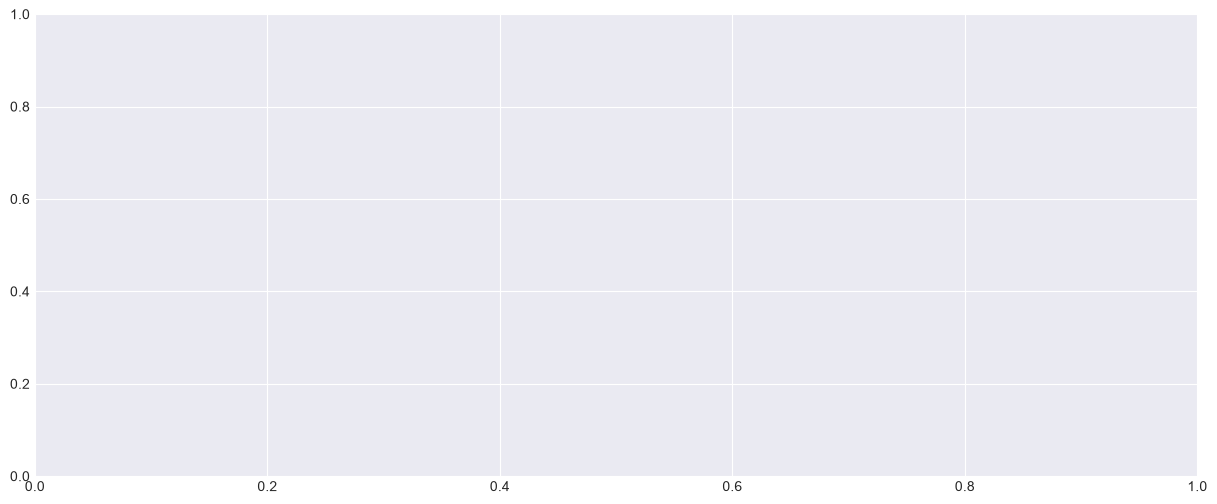

In [190]:
plot_decision_boundary(model,X_train,y_train, X_test,y_test)

In [ ]:
#training accuracy
predictions = []
for row in X_train:
    a = fn_predict(model, row.reshape(1, -1))
    y_p = 1 if a >= 0.5 else 0
    predictions.append(y_p)
    
f_score = f1_score(y_train.argmax(axis=1).ravel(), predictions)
accuracy_score(y_train.argmax(axis=1).ravel(), predictions)
 

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])


fig, ax = plt.subplots(figsize=(4, 4))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
plt.title(f'Training accuracy: {f_score}')
plt.grid(False)  
plt.show()

ValueError: shapes (1,4) and (2,4) not aligned: 4 (dim 1) != 2 (dim 0)

In [ ]:
## Testing Data

In [ ]:
#test accuracy
predictions = []
for row in X_test:
    a = fn_predict(model, row.reshape(1, -1))
    y_p = 1 if a >= 0.5 else 0
    predictions.append(y_p)

f_score = f1_score(y_test.argmax(axis=1).ravel(), predictions)
accuracy_score(y_test.argmax(axis=1).ravel(), predictions)

ValueError: shapes (1,4) and (2,4) not aligned: 4 (dim 1) != 2 (dim 0)

In [ ]:
test_preds = fn_predict(model, X_test).astype(int)
cm = confusion_matrix(y_test.argmax(axis=1).ravel(), test_preds)
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])

fig, ax = plt.subplots(figsize=(4, 4))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
plt.title(f'Testing accuracy: {f_score}')
plt.grid(False)  
plt.show()

ValueError: shapes (30,4) and (2,4) not aligned: 4 (dim 1) != 2 (dim 0)